# Clustering: host types (Group A, Airbnb NYC Pricing Segments)

**Owner:** Fedi. **Handover:** `host_types.csv` to Dragos, Thu 12 Nov 2026.

**Goal:** group the hosts into types, using how they run their listings. Price and reviews are **not** used to build the groups (team rule, Lara). They are only used afterwards to describe the groups.

**Input:** `data/processed/hosts.csv` (one row per host, built by Lara in `02_data_cleaning.ipynb`, section 11).
**Output:** `data/processed/host_types.csv` with `host_id`, `host_type`, `host_type_label`.

**AI use:** first draft of this notebook written with an AI tool (Claude) from my plan and the team's rules. I checked, ran and edited every cell.

## 0. Settings (my decisions)

Two choices are mine. They are set here so every run uses the same values, and so the decision log at the end matches the code.

In [39]:
# the notebook sits in notebooks/, so the data is one folder up
# (in colab, from the repo root, it would be "data/processed/")
DATA_DIR = "../data/processed/"

# the chart for the report goes in reports/figures, where the team keeps them
FIG_DIR = "../reports/figures/"

# my first decision: which availability feature we use to build the groups
# avg_availability is the average days open per year (0 to 365)
# share_zero_availability is the share of the host's listings at 0 days, but for most hosts it's just 0 or 1
# we keep avg_availability, section 3 shows why
AVAILABILITY_FEATURE = "avg_availability"

# my second decision: how many host types. we choose it in section 4 and 5
K = 7

# we fix the seed so we get the exact same groups at every run
SEED = 42

In [40]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score

# wider tables so the profiles fit on one line
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# we print the versions, so anyone can rerun this later and get the same numbers
print("Python", sys.version.split()[0])
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.15
pandas 3.1.1 | numpy 2.5.4 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 1. Load and check the host table

In [41]:
# hosts.csv is lara's host table: one row per host, built in 02_data_cleaning (section 11)
hosts = pd.read_csv(DATA_DIR + "hosts.csv")
print("Rows (hosts):", len(hosts))
print("Columns:", list(hosts.columns))
print()
print("Missing values per column:")
print(hosts.isna().sum())

Rows (hosts): 37457
Columns: ['host_id', 'n_listings', 'avg_availability', 'share_zero_availability', 'share_entire_home', 'median_min_nights', 'n_neighbourhood_groups']

Missing values per column:
host_id                     0
n_listings                  0
avg_availability            0
share_zero_availability     0
share_entire_home           0
median_min_nights          13
n_neighbourhood_groups      0
dtype: int64


In [42]:
hosts.describe().round(2)

,host_id,n_listings,avg_availability,share_zero_availability,share_entire_home,median_min_nights,n_neighbourhood_groups
count,3.745700e+04,37457.00,37457.00,37457.00,37457.00,37444.00,37457.00
mean,6.144549e+07,1.31,88.29,0.43,0.55,5.68,1.00
std,7.511750e+07,2.76,118.35,0.49,0.49,15.96,0.06
min,2.438000e+03,1.00,0.00,0.00,0.00,1.00,1.00
25%,7.050126e+06,1.00,0.00,0.00,0.00,1.50,1.00
50%,2.679050e+07,1.00,16.00,0.00,1.00,2.50,1.00
75%,8.817184e+07,1.00,164.00,1.00,1.00,4.00,1.00
max,2.743213e+08,327.00,365.00,1.00,1.00,365.00,4.00


**What to notice:**
- 13 hosts have no `median_min_nights`. All their listings had a minimum stay above 365 nights and were removed in cleaning. K-means can't use a row with a gap, so I drop them. They have no listings left, so no price gap is lost.
- `n_neighbourhood_groups` is 1 for almost every host (checked in the next cell). A column that hardly varies adds nothing to the groups, so I leave it out.

In [43]:
# almost every host is in one borough only, so this column can't separate anyone. we leave it out
print("Share of hosts in exactly 1 borough:", round((hosts["n_neighbourhood_groups"] == 1).mean(), 3))

# 13 hosts have no minimum stay because all their listings were over 365 nights and got removed in cleaning
# k-means can't work with an empty value, and these hosts have no listings left anyway, so we drop them
hosts = hosts.dropna(subset=["median_min_nights"]).copy()
print("Hosts kept:", len(hosts))

Share of hosts in exactly 1 borough: 0.997
Hosts kept: 37444


## 2. Build the features

- **Listing count:** from 1 to 327, very skewed. I take the log so a host with 327 listings doesn't swamp everything.
- **Minimum stay:** median 2.5 nights, max 365. Also skewed, so also logged.
- **Share of entire homes:** already between 0 and 1.
- **Availability:** the feature chosen in section 0.

Then every feature is standardised (mean 0, standard deviation 1), so each one has the same say in the distance (Unit 5; Géron ch. 8).

In [44]:
# listings go from 1 to 327 and minimum stay from 1 to 365 nights, so a few hosts would decide everything
# we take the log: 327 listings becomes 5.8 instead of 327
hosts["log_n_listings"] = np.log(hosts["n_listings"])
hosts["log_min_nights"] = np.log(hosts["median_min_nights"])

# the 4 features that build the groups. no price and no reviews (team rule), they only describe the groups after
FEATURES = ["log_n_listings", "log_min_nights", "share_entire_home", AVAILABILITY_FEATURE]

# we standardise so each feature has the same weight in the distance
# without it, days available (0 to 365) would count much more than the share of entire homes (0 to 1)
scaler = StandardScaler()
X = scaler.fit_transform(hosts[FEATURES])
print("Feature matrix:", X.shape)

Feature matrix: (37444, 4)


## 3. Why not the 0/1 availability feature? (the rejected option)

86% of hosts have one listing. For them, `share_zero_availability` and `share_entire_home` are exactly 0 or 1. Hosts with the same 0/1 values sit at distance 0 from each other, which pushes the silhouette score up even when the groups mean little.

This cell runs both versions at k = 5 and compares them, so the choice is backed by numbers.

In [45]:
# small helper so we can run the same k-means on two different feature lists and compare them
def run_kmeans(feature_list, k, seed):
    matrix = StandardScaler().fit_transform(hosts[feature_list])
    # n_init=10: k-means runs 10 times from different starts and keeps the best one
    model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(matrix)
    # silhouette on 10,000 hosts: on all 37,444 it compares every pair and takes too long
    score = silhouette_score(matrix, model.labels_, sample_size=10000, random_state=seed)
    return model.labels_, score

# same 3 features, only the availability one changes
base = ["log_n_listings", "log_min_nights", "share_entire_home"]
labels_zero, sil_zero = run_kmeans(base + ["share_zero_availability"], 5, SEED)
labels_avg, sil_avg = run_kmeans(base + ["avg_availability"], 5, SEED)
print("Silhouette at k = 5, share_zero_availability:", round(sil_zero, 3))
print("Silhouette at k = 5, avg_availability:       ", round(sil_avg, 3))

# what's inside the 0/1 groups? we look at single-listing hosts only (86% of hosts)
# if each group sits in one column, k-means just found the yes/no combinations, nothing more
single = hosts["n_listings"] == 1
check = pd.crosstab(pd.Series(labels_zero[single.values], name="group"),
                    [hosts.loc[single, "share_entire_home"].round(0).values, hosts.loc[single, "share_zero_availability"].round(0).values],
                    colnames=["entire home", "0 days available"])
print()
print("Single-listing hosts, groups (rows) vs entire home and 0 days available (columns):")
print(check)

Silhouette at k = 5, share_zero_availability: 0.523
Silhouette at k = 5, avg_availability:        0.456

Single-listing hosts, groups (rows) vs entire home and 0 days available (columns):
entire home        0.0          1.0      
0 days available   0.0   1.0    0.0   1.0
group                                    
0                    0     0      0  8098
1                    0     0  10889     0
3                 6491     0      0     0
4                    0  6812      0     0


**Reading it:** if each group (row) sits almost entirely in one column, the 0/1 version only rediscovers the yes/no combinations, which a simple cross-table would give. That's why a higher silhouette is not enough here.

## 4. Choosing k: elbow (SSE) and silhouette

SSE always falls when k rises, so I look for where the drop slows (the elbow). The silhouette peaks instead. The silhouette is computed on a sample of 10,000 hosts to keep it fast; the seed keeps the sample the same every run.

In [46]:
# we try 2 to 10 host types and keep the 2 scores for each
k_values = list(range(2, 11))
sse_values = []
silhouette_values = []

# sse (inertia) always goes down when k goes up, so we look for where it stops dropping much (the elbow)
# silhouette goes up then down, so the peak is the best separation
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    sse_values.append(model.inertia_)
    silhouette_values.append(silhouette_score(X, model.labels_, sample_size=10000, random_state=SEED))

results = pd.DataFrame({"k": k_values, "SSE": np.round(sse_values), "silhouette": np.round(silhouette_values, 3)})
print(results.to_string(index=False))

 k      SSE  silhouette
 2 110688.0       0.347
 3  84541.0       0.388
 4  65423.0       0.427
 5  52217.0       0.456
 6  46010.0       0.473
 7  40293.0       0.484
 8  35956.0       0.471
 9  31949.0       0.435
10  30004.0       0.439


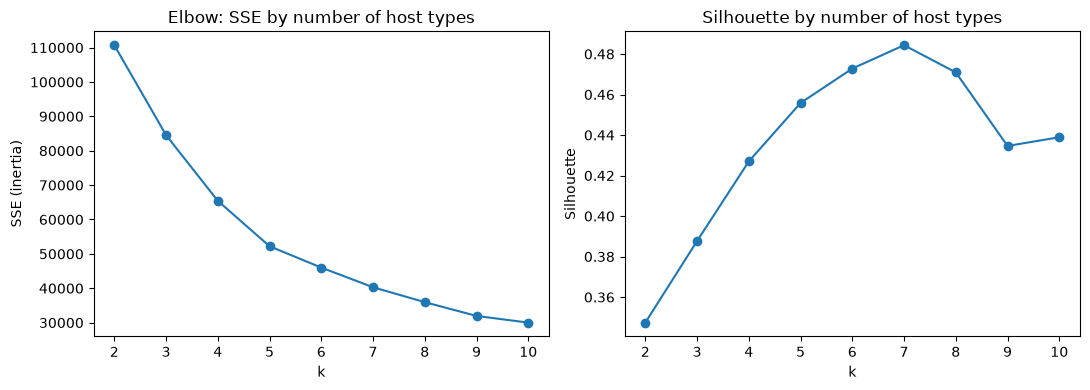

In [47]:
# the same 2 scores as a chart, easier to see the elbow and the peak
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_values, sse_values, marker="o")
axes[0].set_title("Elbow: SSE by number of host types")
axes[0].set_xlabel("k")
axes[0].set_ylabel("SSE (inertia)")
axes[1].plot(k_values, silhouette_values, marker="o")
axes[1].set_title("Silhouette by number of host types")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

## 5. Are the groups stable?

K-means starts from random centres. If other seeds give different groups, the groups are fragile. The adjusted Rand index (ARI) compares two groupings: 1 means identical.

In [48]:
# k-means starts from random centres. if another seed gives other groups, the groups are not reliable
# we compare seed 42 with seeds 0, 1 and 2. ARI = 1 means exactly the same groups
for k in [5, 6, 7, 8]:
    reference = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)
    scores = []
    for other_seed in [0, 1, 2]:
        other = KMeans(n_clusters=k, n_init=10, random_state=other_seed).fit_predict(X)
        scores.append(adjusted_rand_score(reference, other))
    print("k =", k, " mean ARI vs seeds 0, 1, 2:", round(np.mean(scores), 3))

k = 5  mean ARI vs seeds 0, 1, 2: 1.0
k = 6  mean ARI vs seeds 0, 1, 2: 1.0
k = 7  mean ARI vs seeds 0, 1, 2: 1.0
k = 8  mean ARI vs seeds 0, 1, 2: 0.929


## 6. Final model and group profiles

Fit with the K chosen in section 0. Group numbers have no order; with the same settings and seed they stay the same. The profile uses the building features. Price and reviews come from `listings_clean.csv` and are **descriptors only**: each host's median listing price, then the median across hosts in the group.

In [49]:
# the final model with my K. each host gets a group number (0 to K-1)
final_model = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X)
hosts["host_type"] = final_model.labels_

# we read the listings only to describe the groups, never to build them
listings = pd.read_csv(DATA_DIR + "listings_clean.csv")
# one line per host: median price of their listings, reviews, and their most recent review
# most recent review = the smallest days_since_last_review among the host's listings
per_host = listings.groupby("host_id").agg(median_price=("price", "median"),
                                           median_reviews_per_month=("reviews_per_month", "median"),
                                           has_any_review=("has_reviews", "max"),
                                           days_since_latest_review=("days_since_last_review", "min")).reset_index()
profile_data = hosts.merge(per_host, on="host_id", how="left")

# one row per group: what the hosts look like, then price and reviews as descriptors
profile = profile_data.groupby("host_type").agg(
    hosts=("host_id", "size"),
    listings=("n_listings", "sum"),
    median_listings=("n_listings", "median"),
    hosts_10_plus=("n_listings", lambda s: (s >= 10).sum()),
    median_days_available=("avg_availability", "median"),
    share_entire_home=("share_entire_home", "mean"),
    median_min_nights=("median_min_nights", "median"),
    median_price_usd=("median_price", "median"),
    median_reviews_per_month=("median_reviews_per_month", "median"),
).round(2)
profile

,hosts,listings,median_listings,hosts_10_plus,median_days_available,share_entire_home,median_min_nights,median_price_usd,median_reviews_per_month
host_type,,,,,,,,,
0,9799,9799,1.0,0,0.0,0.00,2.0,70.0,0.14
1,12893,12893,1.0,0,0.0,1.00,3.0,150.0,0.24
2,1189,7951,4.0,115,263.0,0.29,2.0,75.0,1.00
3,4539,4813,1.0,0,261.0,1.00,2.0,180.0,1.62
4,3036,6764,2.0,0,53.0,0.31,2.0,90.0,0.92
5,3077,3393,1.0,0,70.0,0.66,30.0,111.0,0.11
6,2911,3269,1.0,0,303.0,0.01,2.0,79.0,0.76


**Are the 0-day groups booked or inactive?** 0 days available can mean fully booked or switched off. Two more descriptors help: the share of hosts with no review at all, and how long since their latest review. The file's latest review is 8 July 2019, so "more than 365 days" means no review since mid-2018.

In [50]:
# 0 days available can mean fully booked or switched off. reviews help us tell which one
# the file's last review is 8 july 2019, so more than 365 days means no review since mid 2018
activity = profile_data.groupby("host_type").agg(
    share_never_reviewed=("has_any_review", lambda s: round(1 - s.mean(), 2)),
    median_days_since_latest_review=("days_since_latest_review", "median"),
    share_no_review_for_a_year=("days_since_latest_review", lambda s: round((s > 365).sum() / len(s), 2)),
)
activity

,share_never_reviewed,median_days_since_latest_review,share_no_review_for_a_year
host_type,,,
0,0.26,246.0,0.31
1,0.19,185.0,0.29
2,0.04,14.0,0.02
3,0.09,15.0,0.04
4,0.05,18.0,0.14
5,0.34,188.0,0.22
6,0.15,27.0,0.09


**Who is in each group, by listing count?** Checks whether a group of "several listings" really holds the big operators, or mostly hosts with 2 or 3 listings.

In [51]:
# how many listings do the hosts in each group have? to check if a "several listings" group is really the big operators
bands = pd.cut(profile_data["n_listings"], bins=[0, 1, 3, 9, 1000], labels=["1", "2 to 3", "4 to 9", "10+"])
pd.crosstab(profile_data["host_type"], bands)

n_listings,1,2 to 3,4 to 9,10+
host_type,,,,
0,9799,0,0,0
1,12893,0,0,0
2,0,390,684,115
3,4265,274,0,0
4,0,2962,74,0
5,2780,296,1,0
6,2553,358,0,0


**Naming the groups (my call):** read each row and give it a short name a manager would understand. Fill the dictionary below. Group numbers come from k-means and have no order; they stay the same as long as the settings and seed don't change.

In [ ]:
# one short name per group, that a manager understands, from the profile, activity and listing tables above
# names checked with lara: "low availability" because 35 to 41% of these hosts still have some days open,
# "long stays" because only half have 30+ nights (94% have 14+), "room" because private and shared rooms are merged
TYPE_LABELS = {
    0: "One room, low availability",
    1: "One entire home, low availability",
    2: "Several listings, open most of the year",
    3: "One entire home, open most of the year",
    4: "2 to 3 listings, rarely open",
    5: "Long stays (2 weeks or more)",
    6: "One room, open most of the year",
}

hosts["host_type_label"] = hosts["host_type"].map(TYPE_LABELS)
hosts["host_type_label"].value_counts()

host_type_label
One entire home, not available             12893
One private room, not available             9799
One entire home, open most of the year      4539
Monthly stays                               3077
2 to 3 listings, rarely open                3036
One private room, open most of the year     2911
Several listings, open most of the year     1189
Name: count, dtype: int64

## 7. Baseline: does k-means beat simple rules?

Like the median-price baseline in the regression, clustering needs a simple comparison. Here: 7 groups a manager could write by hand, on the same information. Both groupings are scored two ways:
- **Silhouette:** how well separated the groups are, in the k-means feature space. This favours k-means by construction.
- **Price variation explained:** the share of the variation in listing log price that the host type accounts for (eta squared). Price is never used to build the groups; it is only used here to judge them. It stands in for the real test, which is how well host types separate the price gaps once the regression predictions are in.

In [53]:
# the baseline: 7 groups a manager could write by hand, with the same information k-means has
# like the median price baseline in the regression, k-means should do better than this to be worth it
def rule_based_type(row):
    if row["n_listings"] >= 10:
        return "10+ listings"
    if row["n_listings"] >= 2:
        return "2 to 9 listings"
    if row["median_min_nights"] >= 30:
        return "single, monthly stays"
    kind = "entire home" if row["share_entire_home"] >= 0.5 else "room"
    open_or_not = "open" if row["avg_availability"] > 0 else "0 days"
    return "single, " + kind + ", " + open_or_not

hosts["rule_type"] = hosts.apply(rule_based_type, axis=1)
print(hosts["rule_type"].value_counts())

rule_type
single, entire home, open      10027
single, entire home, 0 days     7897
single, room, 0 days            6695
single, room, open              6213
2 to 9 listings                 5039
single, monthly stays           1458
10+ listings                     115
Name: count, dtype: int64


In [54]:
# we use the log of price because a few listings at $10,000 would weigh too much
listing_prices = listings[["host_id", "price"]].copy()
listing_prices["log_price"] = np.log(listing_prices["price"])

# how much of the price differences between listings the groups explain (eta squared, 0 to 1)
# price is only used here to judge the groups, never to build them
def price_variance_explained(group_column):
    merged = listing_prices.merge(hosts[["host_id", group_column]], on="host_id")
    grand_mean = merged["log_price"].mean()
    between = 0.0
    for _, group in merged.groupby(group_column):
        between += len(group) * (group["log_price"].mean() - grand_mean) ** 2
    total = ((merged["log_price"] - grand_mean) ** 2).sum()
    return between / total

# silhouette needs numbers, so we turn the rule names into 0, 1, 2...
rule_codes = pd.factorize(hosts["rule_type"])[0]
# silhouette favours k-means here, because it's measured in the same space k-means optimises
comparison = pd.DataFrame({
    "method": ["k-means (k = " + str(K) + ")", "rule-based (7 groups)"],
    "silhouette": [silhouette_score(X, hosts["host_type"], sample_size=10000, random_state=SEED),
                   silhouette_score(X, rule_codes, sample_size=10000, random_state=SEED)],
    "price_variance_explained": [price_variance_explained("host_type"), price_variance_explained("rule_type")],
}).round(3)
print(comparison.to_string(index=False))
print()
print("Agreement between the two groupings (ARI):", round(adjusted_rand_score(hosts["host_type"], rule_codes), 3))

               method  silhouette  price_variance_explained
      k-means (k = 7)       0.484                     0.230
rule-based (7 groups)       0.201                     0.247

Agreement between the two groupings (ARI): 0.497


**Reading it:** if the rules explain price about as well as k-means, k-means' value is not a better price split. Its value is that it found the operating types (monthly stays, open all year, the big operators) without being told. Say this plainly in the method.

## 8. Chart for the report

One chart a manager can read in seconds: how many hosts in each type. The labels come from `TYPE_LABELS`, so fill those first.

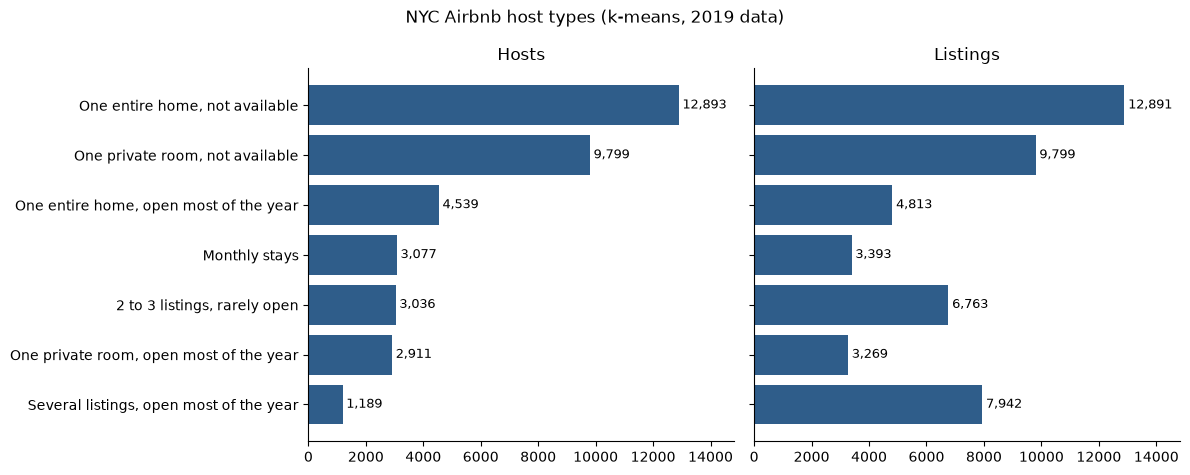

In [55]:
# we create the figures folder if it's not in the repo yet
os.makedirs(FIG_DIR, exist_ok=True)

# hosts per type, and listings per type counted in the cleaned listings (the ones that get a price gap)
host_counts = hosts["host_type_label"].value_counts()
listing_types = listings.merge(hosts[["host_id", "host_type_label"]], on="host_id")
listing_counts = listing_types["host_type_label"].value_counts()

# same order in both panels: biggest number of hosts at the top
order = host_counts.sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
panels = [(axes[0], host_counts[order], "Hosts"), (axes[1], listing_counts.reindex(order), "Listings")]
for ax, values, title in panels:
    ax.barh(order, values.values, color="#2f5d8a")
    # the number written at the end of each bar
    for position, value in enumerate(values.values):
        ax.text(value + max(values.values) * 0.01, position, f"{value:,}", va="center", fontsize=9)
    ax.set_title(title)
    ax.set_xlim(0, max(values.values) * 1.15)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("NYC Airbnb host types (k-means, 2019 data)")
plt.tight_layout()
# dpi=200 so the chart stays sharp in the report
plt.savefig(FIG_DIR + "host_types.png", dpi=200)
plt.show()

## 9. One try with DBSCAN (team open question 10)

DBSCAN finds dense regions and marks sparse points as noise. It needs no k, but it needs `eps` (the radius) and `min_samples`. One documented try on a sample, to say whether it's worth more time.

In [56]:
# one try only, on 10,000 hosts, to see if dbscan is worth more time
rng = np.random.default_rng(SEED)
sample_rows = rng.choice(len(X), size=10000, replace=False)

# eps is the radius around each host, min_samples how many neighbours make a dense area
# hosts in no dense area are noise (label -1)
for eps in [0.3, 0.5]:
    labels = DBSCAN(eps=eps, min_samples=20).fit_predict(X[sample_rows])
    n_groups = len(set(labels)) - (1 if -1 in labels else 0)
    noise_share = (labels == -1).mean()
    largest_share = pd.Series(labels).value_counts(normalize=True).iloc[0]
    print("eps", eps, ": groups", n_groups, ", noise", round(noise_share, 3), ", largest group share", round(largest_share, 3))

eps 0.3 : groups 15 , noise 0.119 , largest group share 0.172
eps 0.5 : groups 10 , noise 0.066 , largest group share 0.412


## 10. Save the handover file

In [57]:
# the file for dragos: one row per host, he joins it to the price gaps on host_id
handover = hosts[["host_id", "host_type", "host_type_label"]]
handover.to_csv(DATA_DIR + "host_types.csv", index=False)
print("Saved", len(handover), "rows to", DATA_DIR + "host_types.csv")

Saved 37444 rows to ../data/processed/host_types.csv


## 11. Decision log

| Decision | Choice | Why |
|---|---|---|
| Unit | Hosts, not listings | Hosts are Airbnb's customers (Ahmed) |
| Building features | log listing count, log min stay, share entire home, availability | How a host runs listings; no price or reviews (Lara's rule) |
| Left out | `n_neighbourhood_groups` | Same value for almost every host |
| Dropped rows | 13 hosts without `median_min_nights` | No listings left after cleaning |
| Availability feature | `avg_availability` | The 0/1 version scores higher (silhouette 0.52 vs 0.46 at k = 5), but its groups are only the yes/no combinations a cross-table would give (section 3) |
| k | 7 | Silhouette peaks at k = 7 (0.484), no clear elbow in the SSE. Same groups with seeds 0, 1, 2 and 42 (ARI 1.0; k = 8 drops to 0.93). First k where the 115 hosts with 10+ listings get their own group. Each group can be named (section 6) |
| Baseline | Rule-based 7 groups | Simple rules explain slightly more of the price variation (24.7%) than k-means (23.0%). K-means' value is finding the operating types without being told, not a better price split. The real test is the price gaps, in the combined analysis (Dragos) |
| DBSCAN | Not used | One try on 10,000 hosts: 15 groups and 12% noise at eps 0.3, 10 groups with one holding 41% at eps 0.5. Too sensitive to its settings |
| Group names | See `TYPE_LABELS` | From the profile, activity and listing tables, then checked by Lara: "low availability" (35 to 41% of these hosts have some days open), "long stays" (94% have 14+ nights, only 52% have 30+), "room" (private and shared rooms are merged) |
| Seed | 42 | Same groups on every run, checked on two different machines |